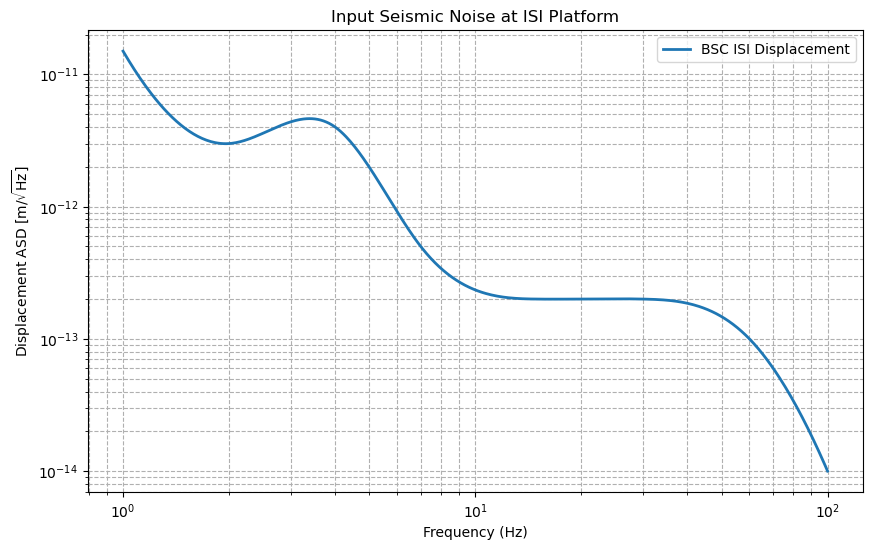

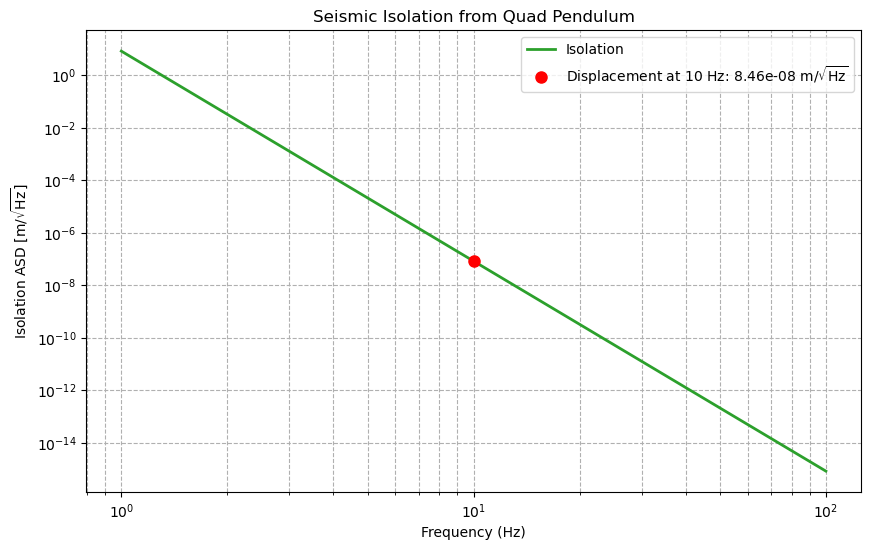

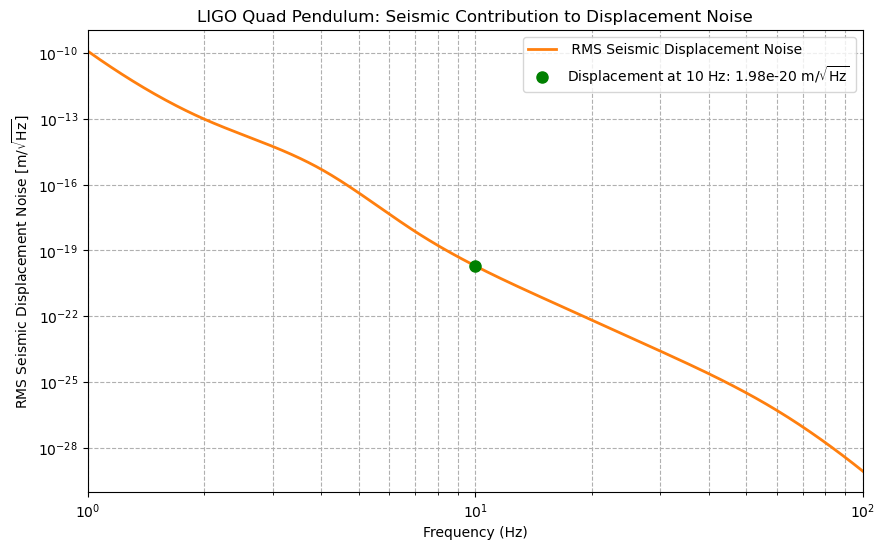

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

def longitudinal_isolation(f, m1, m2, m3, m4, L1, L2, L3, L4):
    g = 9.81
    omega = (2 * np.pi * f)**8
    
    mass_product = m1 * m2 * m3 * m4
    mass_sum_term = (m1+m2+m3+m4) * (m2+m3+m4) * (m3+m4) * m4
    mass_ratio = mass_sum_term / mass_product
    
    length_product = L1 * L2 * L3 * L4
    
    isolation = (g**4 / omega) * (1 / length_product) * mass_ratio
    
    return isolation

#Parameters
m1, m2, m3, m4 = 22, 22, 40, 40
L1, L2, L3, L4 = 0.34, 0.34, 0.34, 0.60
L_arm = 4000 # Arm length of LIGO in meters

# Frequency Range
f = np.logspace(0, 2, 500) # From 1 Hz to 100 Hz

#Strain Conversion
#asd_ground = (1e-9) / f**2

#seismic ground motion (ASD in m/sqrt(Hz))
def seisBSC(f):#Python version of the seisBSC MATLAB function to calculates the seismic noise ASD of the LIGO ISI platform.
    
    # Translational DOFs lookup table
    SEI_F_trans = np.array([0.01, 0.03, 0.1, 0.2, 0.5, 1, 2, 4, 7, 15, 30, 60, 100, 1e6])
    SEI_X_trans = np.array([3e-6, 1e-6, 2e-7, 2e-7, 1e-9, 1.5e-11, 3e-12, 4e-12, 5e-13, 2e-13, 2e-13, 1e-13, 1e-14, 1e-14])
    
    # Creating an interpolator function in log-log space
    # The fill_value sets the noise floor for frequencies outside the table's range
    log_interpolator = interp1d(np.log(SEI_F_trans), np.log(SEI_X_trans), 
                                kind='cubic', bounds_error=False, fill_value=np.log(1e-14))
    # Apply the interpolator to the input frequency array and convert back from log to linear scale
    nx = np.exp(log_interpolator(np.log(f)))
    
    return nx

#Calculate the isolation transfer function
isolation_transfer_function = longitudinal_isolation(f, m1, m2, m3, m4, L1, L2, L3, L4)

#resulting motion of the test mass (ASD in m/sqrt(Hz))
asd_ground=seisBSC(f)
asd_test_mass = asd_ground * isolation_transfer_function

#isolation at 10 Hz
value_at_10hz = np.interp(10, f, isolation_transfer_function)
value_at10hz =np.interp(10, f, asd_test_mass)

#Plots

#BSC ISI Displacement Noise
plt.figure(figsize=(10, 6))
plt.loglog(f, asd_ground, label='BSC ISI Displacement', linewidth=2, color='C0')
plt.title('Input Seismic Noise at ISI Platform')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Displacement ASD [m/$\\sqrt{\mathrm{Hz}}$]') 
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

#Isolation
plt.figure(figsize=(10, 6))
plt.loglog(f, isolation_transfer_function, label='Isolation', linewidth=2, color='C2')
plt.loglog(10, value_at_10hz, 'o',markersize=8, color='red',label=f'Displacement at 10 Hz: {value_at_10hz:.2e} m/$\\sqrt{{\mathrm{{Hz}}}}$')
plt.title('Seismic Isolation from Quad Pendulum')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Isolation ASD [m/$\\sqrt{\mathrm{Hz}}$]') 
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

#Seismic Displacement Noise
plt.figure(figsize=(10, 6))
plt.loglog(f, asd_test_mass, label=' RMS Seismic Displacement Noise', linewidth=2,color='C1')
plt.loglog(10, value_at10hz, 'o',markersize=8, color='green',label=f'Displacement at 10 Hz: {value_at10hz:.2e} m/$\\sqrt{{\mathrm{{Hz}}}}$')
plt.title('LIGO Quad Pendulum: Seismic Contribution to Displacement Noise')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Seismic Displacement Noise [m/$\\sqrt{\mathrm{Hz}}$]')
plt.grid(True, which="both", ls="--")
plt.xlim(1e0,1e2)
plt.legend()
plt.show()




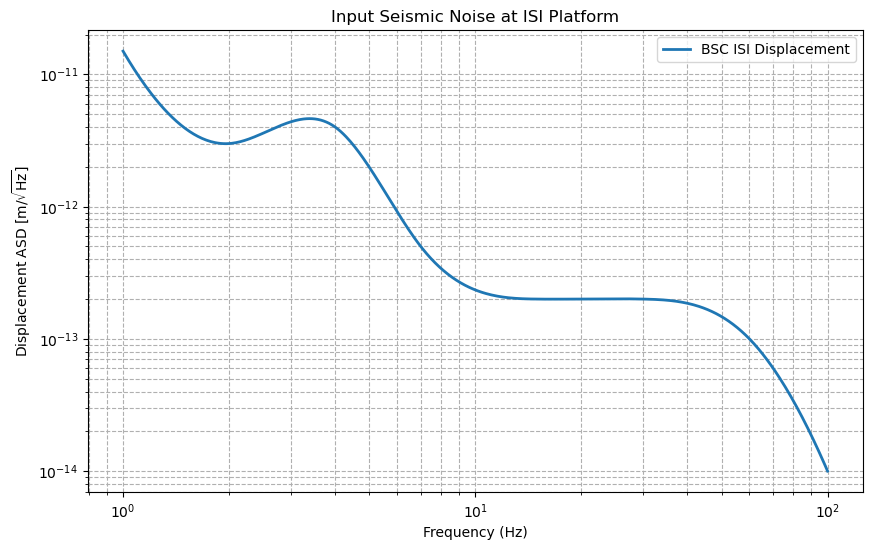

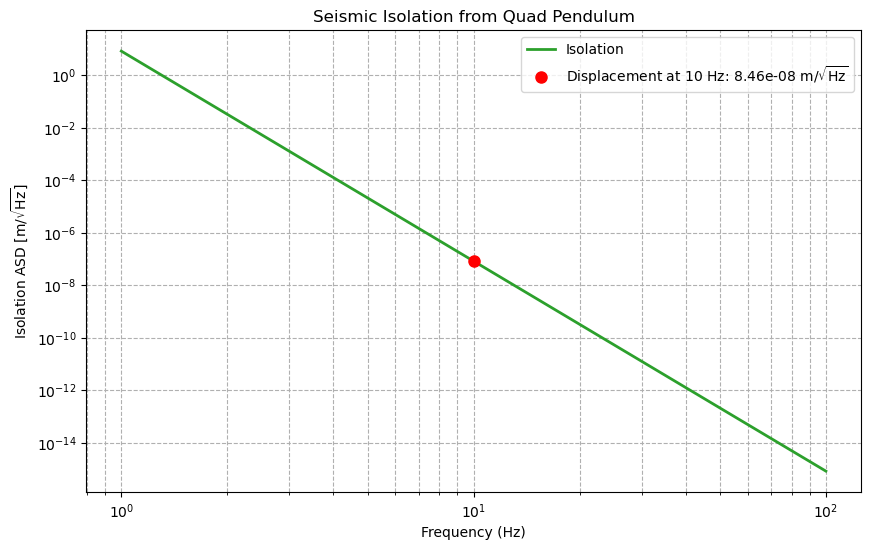

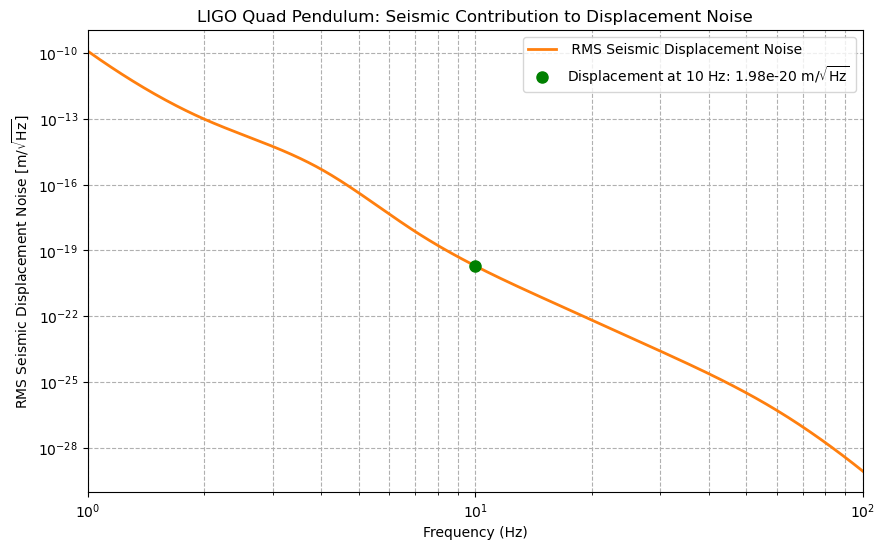

In [5]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

def longitudinal_isolation(f, m1, m2, m3, m4, L1, L2, L3, L4):
    g = 9.81
    omega = (2 * np.pi * f)**8
    
    mass_product = m1 * m2 * m3 * m4
    mass_sum_term = (m1+m2+m3+m4) * (m2+m3+m4) * (m3+m4) * m4
    mass_ratio = mass_sum_term / mass_product
    
    length_product = L1 * L2 * L3 * L4
    
    isolation = (g**4 / omega) * (1 / length_product) * mass_ratio
    
    return isolation

#Parameters
m1, m2, m3, m4 = 22, 22, 40, 40
L1, L2, L3, L4 = 0.34, 0.34, 0.34, 0.60
L_arm = 4000 # Arm length of LIGO in meters

# Frequency Range
f = np.logspace(0, 2, 500) # From 1 Hz to 100 Hz

#Strain Conversion
#asd_ground = (1e-9) / f**2

#seismic ground motion (ASD in m/sqrt(Hz))
def seisBSC(f):#Python version of the seisBSC MATLAB function to calculates the seismic noise ASD of the LIGO ISI platform.
    
    # Translational DOFs lookup table
    SEI_F_trans = np.array([0.01, 0.03, 0.1, 0.2, 0.5, 1, 2, 4, 7, 15, 30, 60, 100, 1e6])
    SEI_X_trans = np.array([3e-6, 1e-6, 2e-7, 2e-7, 1e-9, 1.5e-11, 3e-12, 4e-12, 5e-13, 2e-13, 2e-13, 1e-13, 1e-14, 1e-14])
    
    # Creating an interpolator function in log-log space
    # The fill_value sets the noise floor for frequencies outside the table's range
    log_interpolator = interp1d(np.log(SEI_F_trans), np.log(SEI_X_trans), 
                                kind='cubic', bounds_error=False, fill_value=np.log(1e-14))
    # Apply the interpolator to the input frequency array and convert back from log to linear scale
    nx = np.exp(log_interpolator(np.log(f)))
    
    return nx

#Calculate the isolation transfer function
isolation_transfer_function = longitudinal_isolation(f, m1, m2, m3, m4, L1, L2, L3, L4)

#resulting motion of the test mass (ASD in m/sqrt(Hz))
asd_ground=seisBSC(f)
asd_test_mass = asd_ground * isolation_transfer_function

#isolation at 10 Hz
value_at_10hz = np.interp(10, f, isolation_transfer_function)
value_at10hz =np.interp(10, f, asd_test_mass)

#Plots

#BSC ISI Displacement Noise
plt.figure(figsize=(10, 6))
plt.loglog(f, asd_ground, label='BSC ISI Displacement', linewidth=2, color='C0')
plt.title('Input Seismic Noise at ISI Platform')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Displacement ASD [m/$\\sqrt{\mathrm{Hz}}$]') 
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

#Isolation
plt.figure(figsize=(10, 6))
plt.loglog(f, isolation_transfer_function, label='Isolation', linewidth=2, color='C2')
plt.loglog(10, value_at_10hz, 'o',markersize=8, color='red',label=f'Displacement at 10 Hz: {value_at_10hz:.2e} m/$\\sqrt{{\mathrm{{Hz}}}}$')
plt.title('Seismic Isolation from Quad Pendulum')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Isolation ASD [m/$\\sqrt{\mathrm{Hz}}$]') 
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

#Seismic Displacement Noise
plt.figure(figsize=(10, 6))
plt.loglog(f, asd_test_mass, label=' RMS Seismic Displacement Noise', linewidth=2,color='C1')
plt.loglog(10, value_at10hz, 'o',markersize=8, color='green',label=f'Displacement at 10 Hz: {value_at10hz:.2e} m/$\\sqrt{{\mathrm{{Hz}}}}$')
plt.title('LIGO Quad Pendulum: Seismic Contribution to Displacement Noise')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Seismic Displacement Noise [m/$\\sqrt{\mathrm{Hz}}$]')
plt.grid(True, which="both", ls="--")
plt.xlim(1e0,1e2)
plt.legend()
plt.show()



